Шаг 1: Генерация циклических данных с периодами износа...
Шаг 2: Расчет скользящих средних и дельт...
Размер обучающей выборки: 800, тестовой: 200
Распределение классов в тесте: Штатно (0) = 160, Отказ (1) = 40
Шаг 4: Обучение Random Forest Classifier...

--- Шаг 5: Результаты оценки качества модели ---
              precision    recall  f1-score   support

  Штатно (0)       1.00      0.98      0.99       160
   Отказ (1)       0.93      1.00      0.96        40

    accuracy                           0.98       200
   macro avg       0.97      0.99      0.98       200
weighted avg       0.99      0.98      0.99       200



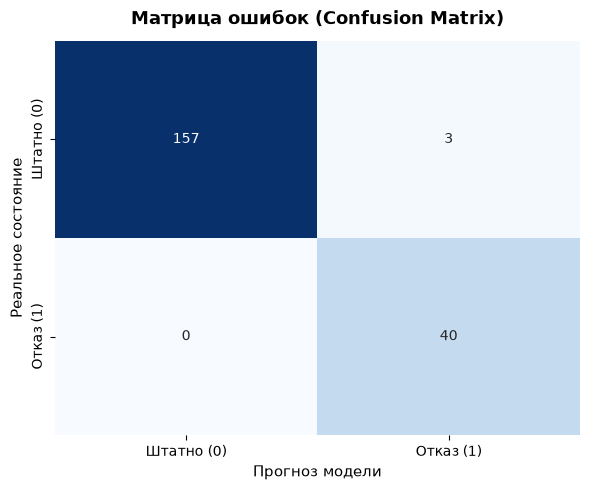

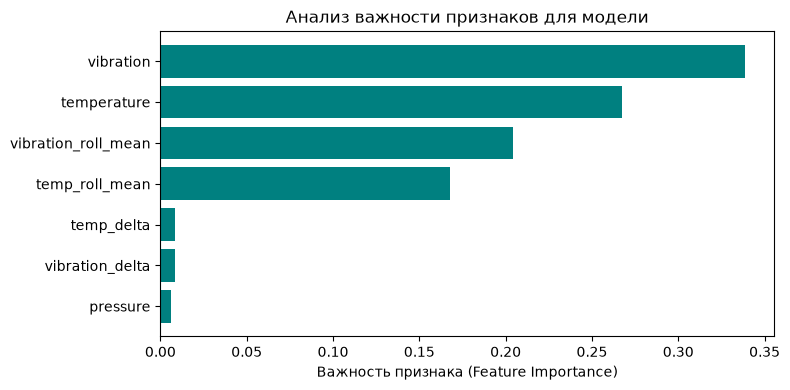

In [1]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Устанавливаем фиксированный random_state для воспроизводимости
np.random.seed(42)

# --- ШАГ 1: ЦИКЛИЧЕСКАЯ ГЕНЕРАЦИЯ ДАННЫХ (ВРЕМЕННЫЕ РЯДЫ) ---
print("Шаг 1: Генерация циклических данных с периодами износа...")

n_steps = 1000  # Общее количество временных шагов (часов)
time_index = pd.date_range(start="2026-01-01", periods=n_steps, freq="h")

# Создаем циклическую симуляцию: оборудование проходит 5 циклов износа
n_cycles = 5
cycle_length = n_steps // n_cycles

vibration_list = []
temperature_list = []
pressure_list = []

for _ in range(n_cycles):
    # Внутри каждого цикла параметры растут от нормальных до аварийных
    vib = np.linspace(0.8, 1.35, cycle_length) + np.random.normal(0, 0.04, cycle_length)
    temp = np.linspace(55.0, 74.0, cycle_length) + np.random.normal(0, 0.8, cycle_length)
    press = np.random.normal(2.0, 0.1, cycle_length)
    
    vibration_list.extend(vib)
    temperature_list.extend(temp)
    pressure_list.extend(press)

df = pd.DataFrame({
    'timestamp': time_index,
    'vibration': vibration_list,
    'temperature': temperature_list,
    'pressure': pressure_list
})

# Физическое правило для отказа: высокая вибрация ИЛИ высокая температура
df['failure'] = ((df['vibration'] > 1.25) | (df['temperature'] > 71.0)).astype(int)

# --- ШАГ 2: FEATURE ENGINEERING (ИНЖЕНЕРИЯ ПРИЗНАКОВ) ---
print("Шаг 2: Расчет скользящих средних и дельт...")

df['vibration_roll_mean'] = df['vibration'].rolling(window=5, min_periods=1).mean()
df['temp_roll_mean'] = df['temperature'].rolling(window=5, min_periods=1).mean()

df['vibration_delta'] = df['vibration'].diff().fillna(0)
df['temp_delta'] = df['temperature'].diff().fillna(0)

features = ['vibration', 'temperature', 'pressure', 'vibration_roll_mean', 'temp_roll_mean', 'vibration_delta', 'temp_delta']
X = df[features]
y = df['failure']

# --- ШАГ 3: ХРОНОЛОГИЧЕСКОЕ РАЗДЕЛЕНИЕ ВЫБОРОК ---
split_index = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

print(f"Размер обучающей выборки: {len(X_train)}, тестовой: {len(X_test)}")
print(f"Распределение классов в тесте: Штатно (0) = {(y_test == 0).sum()}, Отказ (1) = {(y_test == 1).sum()}")

# --- ШАГ 4: ОБУЧЕНИЕ МОДЕЛИ ---
print("Шаг 4: Обучение Random Forest Classifier...")
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

# --- ШАГ 5: ОЦЕНКА КАЧЕСТВА И МЕТРИКИ ---
print("\n--- Шаг 5: Результаты оценки качества модели ---")
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Штатно (0)', 'Отказ (1)']))

# Строим матрицу ошибок
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Штатно (0)', 'Отказ (1)'],
            yticklabels=['Штатно (0)', 'Отказ (1)'])
plt.title('Матрица ошибок (Confusion Matrix)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Прогноз модели', fontsize=11)
plt.ylabel('Реальное состояние', fontsize=11)
plt.tight_layout()
plt.show()

# --- ШАГ 6: АНАЛИЗ ВАЖНОСТИ ПРИЗНАКОВ (XAI) ---
plt.figure(figsize=(8, 4))
importances = model.feature_importances_
sorted_idx = np.argsort(importances)

plt.barh(range(len(sorted_idx)), importances[sorted_idx], color='teal')
plt.yticks(range(len(sorted_idx)), [features[i] for i in sorted_idx])
plt.xlabel('Важность признака (Feature Importance)')
plt.title('Анализ важности признаков для модели')
plt.tight_layout()
plt.show()